<a href="https://colab.research.google.com/github/Ivan-Mayabi/SemProject_MLEngine/blob/main/Regression_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Part 1: Data Entry

In [ ]:
%pip install matplotlib pandas numpy seaborn

In [ ]:
# Import the data set from google drive
from google.colab import drive

drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [ ]:
# Find the data within the path

path = '/content/drive/MyDrive/Colab Notebooks/Year 3 - Artificial Intelligence/Deliverable 1/US_Accidents_March23/US_Accidents_March23.csv'
print(path)

/content/drive/MyDrive/Colab Notebooks/Year 3 - Artificial Intelligence/Deliverable 1/US_Accidents_March23/US_Accidents_March23.csv


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(path,nrows=2500000)

In [ ]:
# Get the actual data needed

Head = df.head(15)
Tail = df.tail(20)
df_sample = pd.concat([Head,Tail],ignore_index=True)

df_sample

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day
5,A-6,Source2,3,2016-02-08 07:44:26,2016-02-08 08:14:26,40.100590,-82.925194,NaN,NaN,0.01,...,False,False,False,False,False,False,Day,Day,Day,Day
6,A-7,Source2,2,2016-02-08 07:59:35,2016-02-08 08:29:35,39.758274,-84.230507,NaN,NaN,0.00,...,False,False,False,False,False,False,Day,Day,Day,Day
7,A-8,Source2,3,2016-02-08 07:59:58,2016-02-08 08:29:58,39.770382,-84.194901,NaN,NaN,0.01,...,False,False,False,False,False,False,Day,Day,Day,Day
8,A-9,Source2,2,2016-02-08 08:00:40,2016-02-08 08:30:40,39.778061,-84.172005,NaN,NaN,0.00,...,False,False,False,False,False,False,Day,Day,Day,Day
9,A-10,Source2,3,2016-02-08 08:10:04,2016-02-08 08:40:04,40.100590,-82.925194,NaN,NaN,0.01,...,False,False,False,False,False,False,Day,Day,Day,Day


 ### Pre-processing

In [ ]:
# Shape of the data

df.shape

(2500000, 46)

In [ ]:
# Show which columns have null data
df.isnull().sum()

,0
ID,0
Source,0
Severity,0
Start_Time,0
End_Time,0
Start_Lat,0
Start_Lng,0
End_Lat,2500000
End_Lng,2500000
Distance(mi),0


### Part 3: EDA

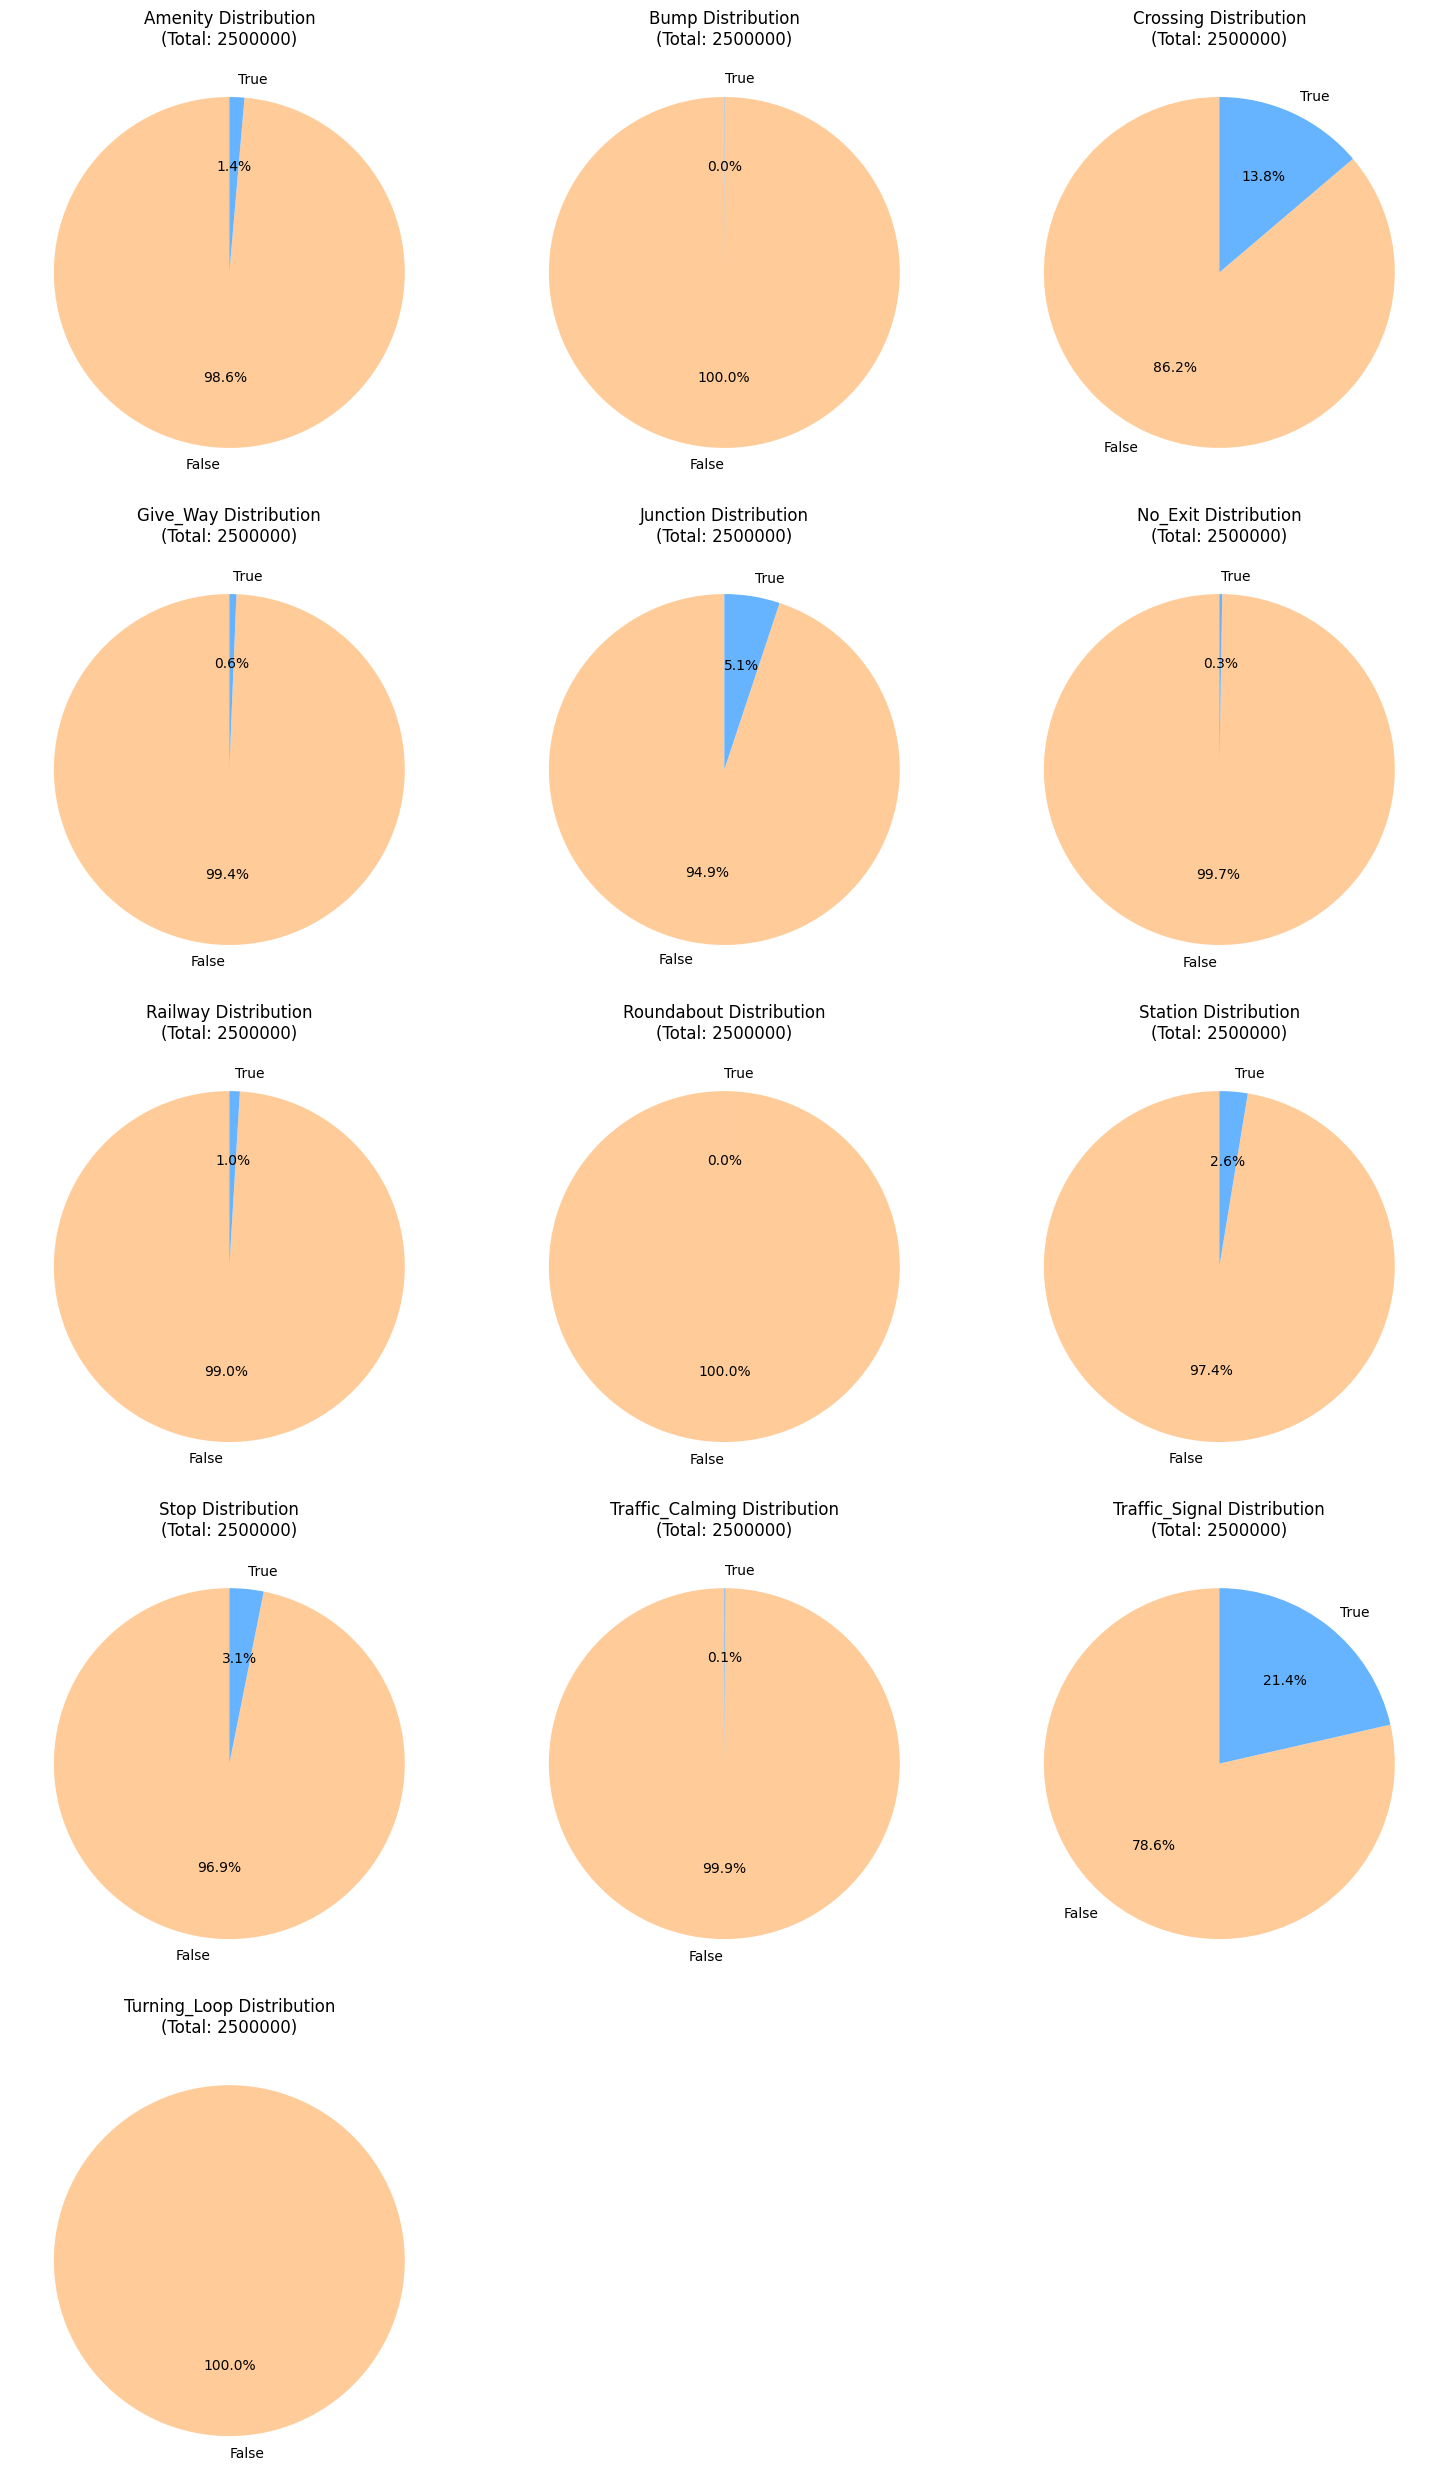

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# List of boolean columns representing road features
road_features = [
    'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction',
    'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop',
    'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop'
]

# Filter to features that are actually in our DataFrame
available_features = [col for col in road_features if col in df.columns]

if available_features:
    # Define the number of plots and grid layout
    n_features = len(available_features)
    cols = 3
    rows = (n_features + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = axes.flatten()

    for i, feature in enumerate(available_features):
        # Count True vs False occurrences for the current feature
        counts = df[feature].value_counts()

        # Ensure we represent True and False explicitly in the labels
        labels = [f'{val}' for val in counts.index]

        # Plotting the pie chart showing True vs False distribution
        axes[i].pie(
            counts,
            labels=labels,
            autopct='%1.1f%%',
            startangle=90,
            colors=['#ffcc99', '#66b3ff']  # Warm and cool colors for comparison
        )
        axes[i].set_title(f'{feature} Distribution\n(Total: {len(df)})')

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()
else:
    print("No matching road feature columns found in the dataset.")

In [ ]:
eda_df = df.copy()

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

eda_df['Start_Time'] = pd.to_datetime(eda_df['Start_Time'], format='mixed', errors='coerce')
eda_df['End_Time'] = pd.to_datetime(eda_df['End_Time'], format='mixed', errors='coerce')

eda_df['hour'] = eda_df['Start_Time'].dt.hour
eda_df['day_name'] = eda_df['Start_Time'].dt.day_name()
eda_df['month'] = eda_df['Start_Time'].dt.month
eda_df['year'] = eda_df['Start_Time'].dt.year
eda_df['is_weekend'] = eda_df['Start_Time'].dt.dayofweek >= 5
eda_df['serious'] = eda_df['Severity'] >= 3
eda_df['duration_min'] = (eda_df['End_Time'] - eda_df['Start_Time']).dt.total_seconds() / 60

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

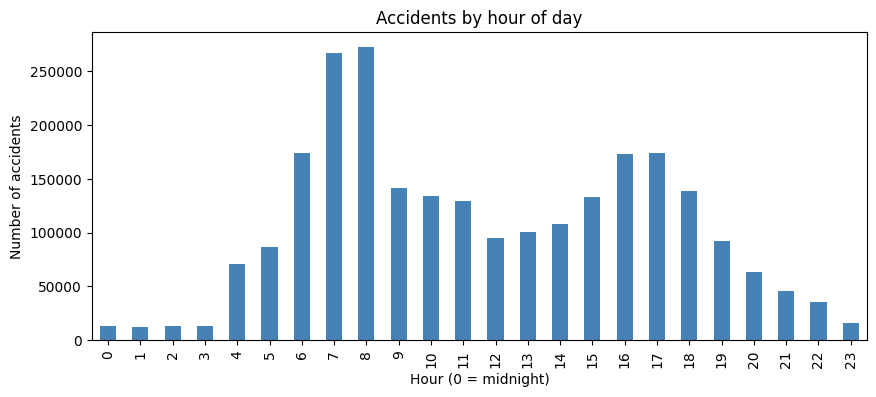

In [ ]:
eda_df['hour'].value_counts().sort_index().plot(kind='bar', figsize=(10, 4), color='steelblue')
plt.title('Accidents by hour of day')
plt.xlabel('Hour (0 = midnight)')
plt.ylabel('Number of accidents')
plt.show()

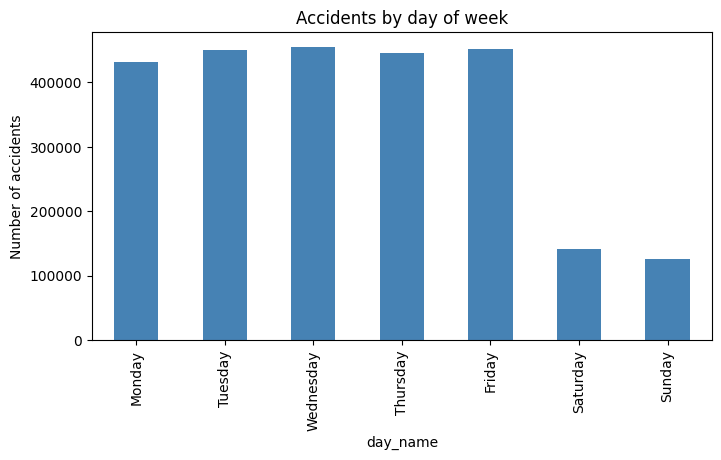

Average accidents per day:
 is_weekend
Weekday    1617.2
Weekend     494.8
Name: count, dtype: float64


In [ ]:
eda_df['day_name'].value_counts().reindex(day_order).plot(kind='bar', figsize=(8, 4), color='steelblue')
plt.title('Accidents by day of week')
plt.ylabel('Number of accidents')
plt.show()

daily = (eda_df.groupby(eda_df['Start_Time'].dt.date)
               .agg(count=('ID', 'count'), is_weekend=('is_weekend', 'first')))
avg = daily.groupby('is_weekend')['count'].mean().rename({False: 'Weekday', True: 'Weekend'})
print("Average accidents per day:\n", avg.round(1))

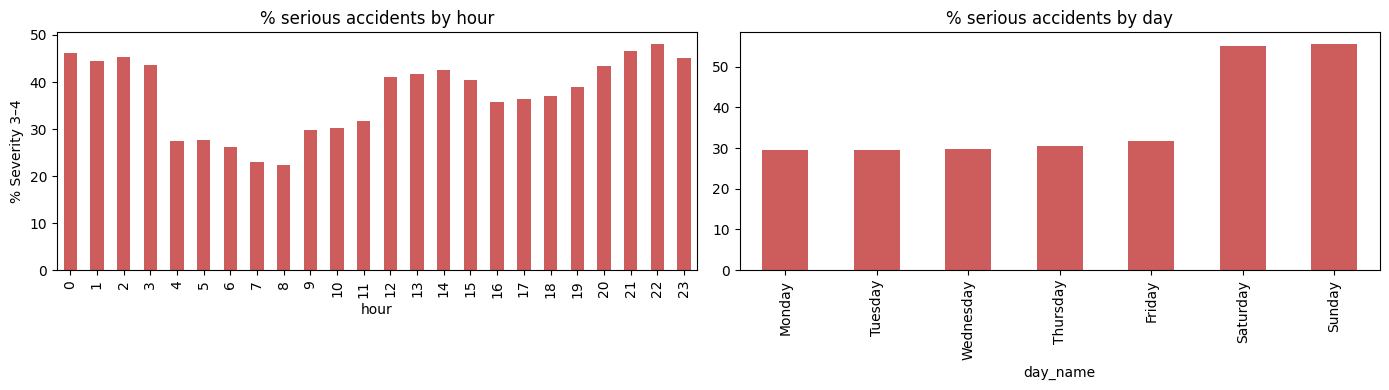

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

(eda_df.groupby('hour')['serious'].mean() * 100).plot(kind='bar', ax=axes[0], color='indianred')
axes[0].set_title('% serious accidents by hour')
axes[0].set_ylabel('% Severity 3–4')

(eda_df.groupby('day_name')['serious'].mean().reindex(day_order) * 100).plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('% serious accidents by day')

plt.tight_layout()
plt.show()

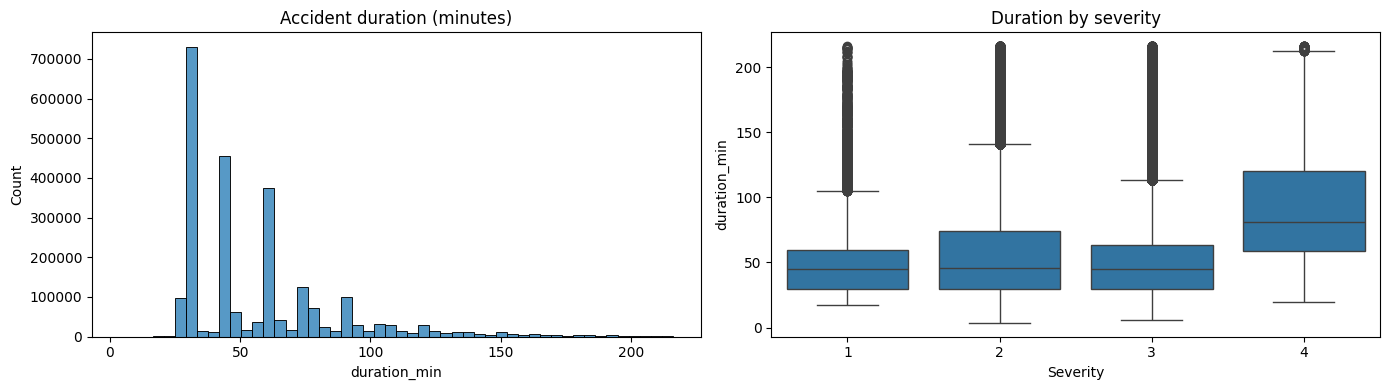

Median duration (min) by severity:
 Severity
1    44.9
2    45.9
3    44.7
4    81.0
Name: duration_min, dtype: float64


In [ ]:
dur = eda_df[eda_df['duration_min'] > 0]
dur = dur[dur['duration_min'] <= dur['duration_min'].quantile(0.99)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(dur['duration_min'], bins=50, ax=axes[0])
axes[0].set_title('Accident duration (minutes)')

sns.boxplot(data=dur, x='Severity', y='duration_min', ax=axes[1])
axes[1].set_title('Duration by severity')
plt.tight_layout()
plt.show()

print("Median duration (min) by severity:\n", dur.groupby('Severity')['duration_min'].median().round(1))

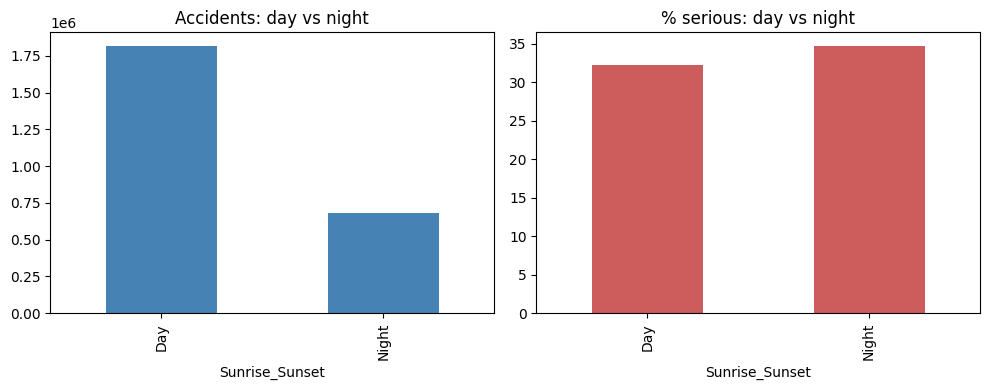

In [ ]:
light = eda_df.dropna(subset=['Sunrise_Sunset'])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
light['Sunrise_Sunset'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Accidents: day vs night')

(light.groupby('Sunrise_Sunset')['serious'].mean() * 100).plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('% serious: day vs night')
plt.tight_layout()
plt.show()

where do accidents happen and what is nearby

In [ ]:
#setting up cell
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# The True/False road-feature columns in this dataset
road_features = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit',
                 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming',
                 'Traffic_Signal', 'Turning_Loop']

# Quick check: these should all be 'bool' for the code to work
print(df[road_features].dtypes.value_counts())

# A temporary True/False Series marking serious accidents (Severity 3 or 4).
# It's stored separately, NOT added to df.
serious = df['Severity'] >= 3

bool    13
Name: count, dtype: int64


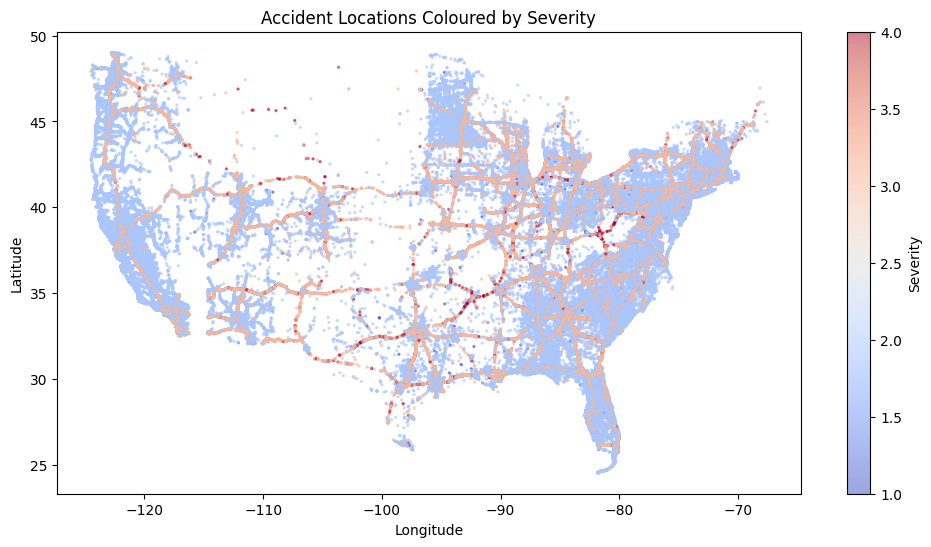

In [ ]:
##Where accidents happen, scatterplot
# Longitude (east-west) goes on the x-axis and latitude (north-south) on the y-axis,
# so the plot reads like a map. Each dot is one accident, coloured by severity.
plt.figure(figsize=(12, 6))
points = plt.scatter(df['Start_Lng'], df['Start_Lat'],
                     c=df['Severity'], cmap='coolwarm', s=2, alpha=0.5)
plt.colorbar(points, label='Severity')
plt.title('Accident Locations Coloured by Severity')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

                 Accidents where True  % of all accidents
Traffic_Signal                 535860               21.43
Crossing                       344621               13.78
Junction                       127441                5.10
Stop                            78523                3.14
Station                         64886                2.60
Amenity                         34549                1.38
Railway                         24013                0.96
Give_Way                        16168                0.65
No_Exit                          6615                0.26
Traffic_Calming                  2524                0.10
Bump                              935                0.04
Roundabout                         91                0.00
Turning_Loop                        0                0.00


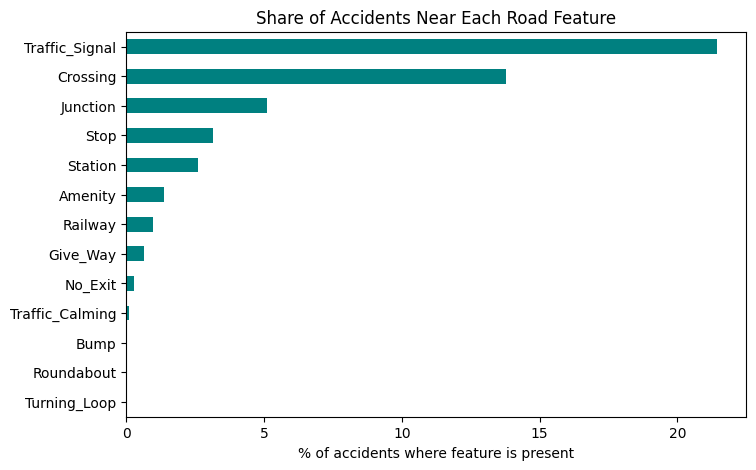

In [ ]:
#how common is each road feature
# Summing a True/False column counts the Trues
feature_counts = df[road_features].sum().sort_values(ascending=False)
feature_pct = feature_counts / len(df) * 100

summary = pd.DataFrame({'Accidents where True': feature_counts,
                        '% of all accidents': feature_pct.round(2)})
print(summary)

plt.figure(figsize=(8, 5))
feature_pct.sort_values().plot(kind='barh', color='teal')
plt.title('Share of Accidents Near Each Road Feature')
plt.xlabel('% of accidents where feature is present')
plt.show()

                 Accidents when True  % serious when True  \
Feature                                                     
Traffic_Signal                535860                  8.6   
Crossing                      344621                  7.1   
Junction                      127441                 54.4   
Stop                           78523                  5.4   
Station                        64886                  9.9   
Amenity                        34549                  6.3   
Railway                        24013                 22.1   
Give_Way                       16168                 16.9   
No_Exit                         6615                 14.8   
Traffic_Calming                 2524                 26.2   
Bump                             935                 25.8   
Roundabout                        91                  3.3   
Turning_Loop                       0                  NaN   

                 % serious when False  Enough data?  
Feature                       

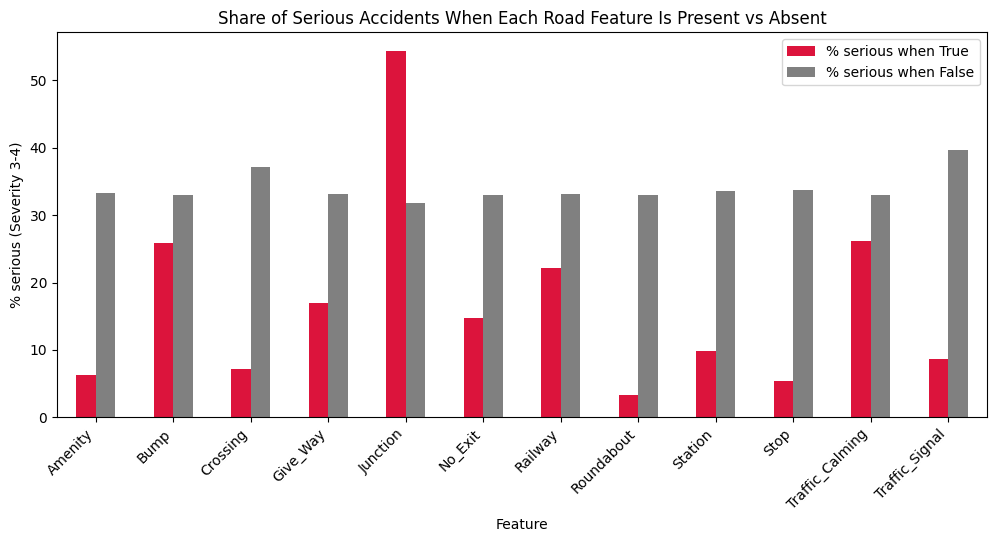

In [ ]:
##serious-accident percentage
# For each feature, split accidents into two piles (feature present / absent)
# and find what % of each pile was serious.
min_true = 30   # fewer True accidents than this = too few to trust (a judgement call)
rows = []

for feature in road_features:
    n_true = int(df[feature].sum())
    pct = serious.groupby(df[feature]).mean() * 100   # % serious in each pile
    rows.append({
        'Feature': feature,
        'Accidents when True': n_true,
        '% serious when True': round(pct.get(True, np.nan), 1),
        '% serious when False': round(pct.get(False, np.nan), 1),
    })

comparison = pd.DataFrame(rows).set_index('Feature')
comparison['Enough data?'] = comparison['Accidents when True'] >= min_true
print(comparison.sort_values('Accidents when True', ascending=False))

# Features with too few True values to draw conclusions from
low_data = comparison[~comparison['Enough data?']].index.tolist()
print('\nToo few cases to trust:', low_data)

# Chart only the features with enough data
trusted = comparison[comparison['Enough data?']]
trusted[['% serious when True', '% serious when False']].plot(
    kind='bar', figsize=(12, 5), color=['crimson', 'grey'])
plt.title('Share of Serious Accidents When Each Road Feature Is Present vs Absent')
plt.ylabel('% serious (Severity 3-4)')
plt.xticks(rotation=45, ha='right')
plt.show()

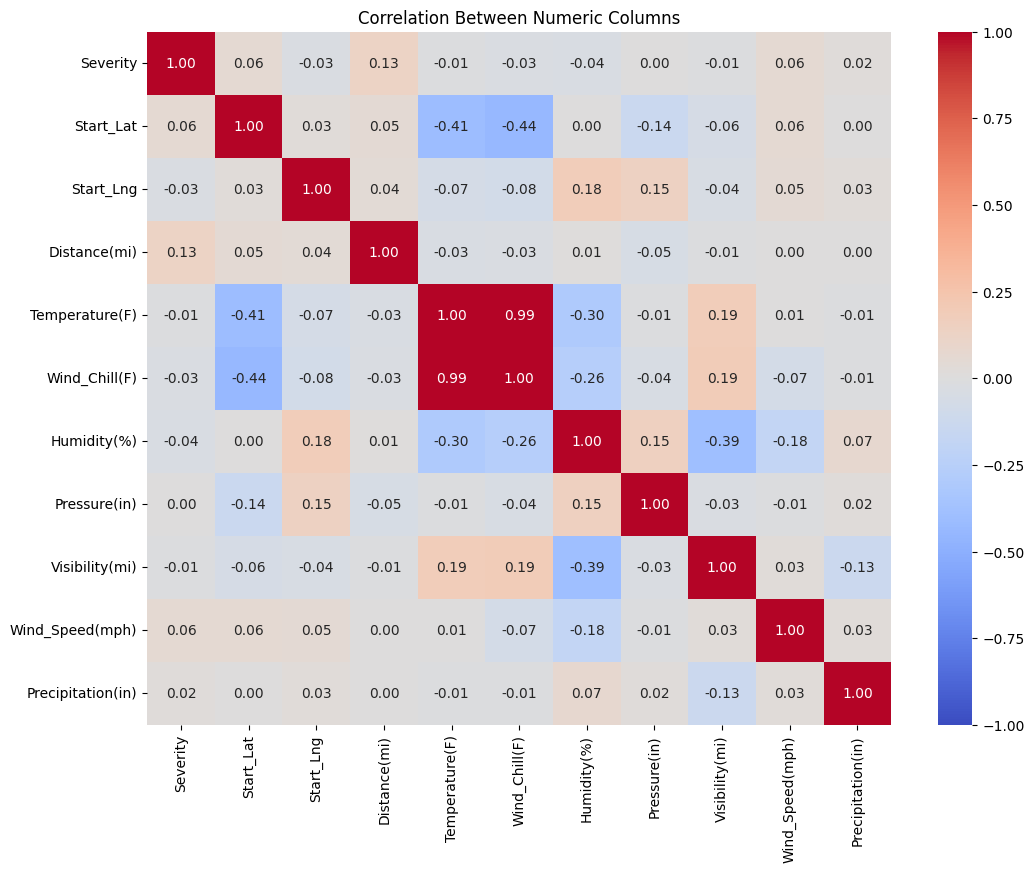

Pairs with correlation of 0.7 or stronger:
Temperature(F)  Wind_Chill(F)    0.99
dtype: float64

Top 10 pairs overall:
Temperature(F)  Wind_Chill(F)      0.99
Start_Lat       Wind_Chill(F)     -0.44
                Temperature(F)    -0.41
Humidity(%)     Visibility(mi)    -0.39
Temperature(F)  Humidity(%)       -0.30
Wind_Chill(F)   Humidity(%)       -0.26
                Visibility(mi)     0.19
Temperature(F)  Visibility(mi)     0.19
Humidity(%)     Wind_Speed(mph)   -0.18
Start_Lng       Humidity(%)        0.18
dtype: float64


In [ ]:
##CORRELATION HEAT MAP OF NUMERICAL VALUES
# Temporary copy of just the numeric columns
numeric = df.select_dtypes(include='number')

# Completely empty columns (End_Lat, End_Lng) can't be correlated, so we
# leave them out of THIS chart only. df itself is not changed.
numeric = numeric.loc[:, numeric.notna().any()]

corr = numeric.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1)
plt.title('Correlation Between Numeric Columns')
plt.show()

##Highly correlated pairs
# Keep only the upper triangle of the matrix so each pair appears once
# (Temperature-Wind_Chill, not also Wind_Chill-Temperature)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

# Turn the grid into a list of pairs, strongest first (ignoring +/- sign)
pairs = upper.stack().sort_values(key=abs, ascending=False)

threshold = 0.7
print(f'Pairs with correlation of {threshold} or stronger:')
print(pairs[pairs.abs() >= threshold].round(2))

print('\nTop 10 pairs overall:')
print(pairs.head(10).round(2))

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Traffic_Signal      -0.264
Crossing            -0.214
Distance(mi)         0.129
Junction             0.103
Stop                -0.102
Station             -0.078
Amenity             -0.065
Wind_Speed(mph)      0.059
Start_Lat            0.056
Humidity(%)         -0.038
Wind_Chill(F)       -0.029
Give_Way            -0.027
Start_Lng           -0.027
Railway             -0.023
No_Exit             -0.020
Precipitation(in)    0.019
Visibility(mi)      -0.012
Temperature(F)      -0.011
Traffic_Calming     -0.005
Pressure(in)         0.003
Roundabout          -0.003
Bump                -0.003
dtype: float64


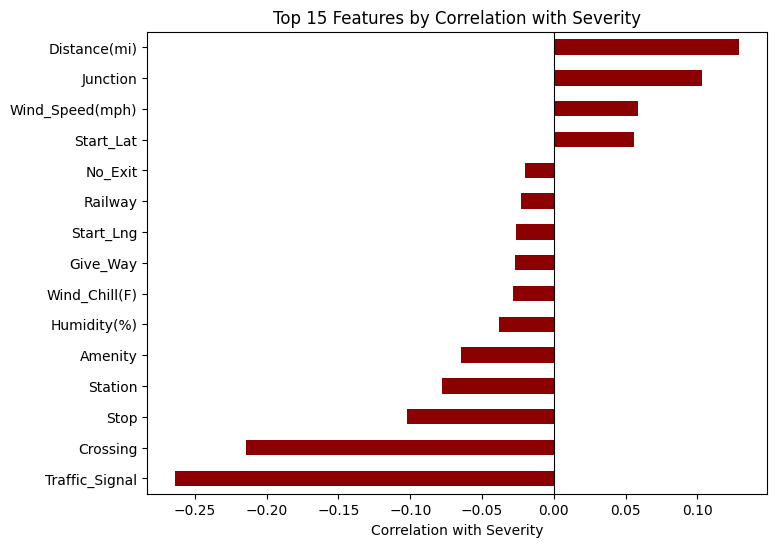

In [ ]:
##Which features are mostly linked to serverity
# Numeric columns plus road features, as a temporary float copy
# (True becomes 1, False becomes 0) so they can all be correlated.
cols = [c for c in numeric.columns if c != 'Severity' and c in df.columns] + road_features
link = df[cols].astype(float).corrwith(df['Severity'])

# Constant columns (e.g. Turning_Loop if it's always False) give NaN,
# so leave them out of this result
link = link.dropna().sort_values(key=abs, ascending=False)
print(link.round(3))

plt.figure(figsize=(8, 6))
link.head(15).sort_values().plot(kind='barh', color='darkred')
plt.title('Top 15 Features by Correlation with Severity')
plt.xlabel('Correlation with Severity')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

### Part 3: Data Cleaning

In [ ]:
df.isnull().sum()


,0
ID,0
Source,0
Severity,0
Start_Time,0
End_Time,0
Start_Lat,0
Start_Lng,0
End_Lat,2500000
End_Lng,2500000
Distance(mi),0


#### Part 3.1 Remove Null columns

Remove End_Lat and End_Lng => Have all their data missing

In [ ]:
df = df.drop(columns=["End_Lat"])
df = df.drop(columns=["End_Lng"])
df.shape

(2500000, 44)

Remove Wind_Chill => Too many fields missing

* In the original dataset, Only 26% of the dataset has this value missing
* However, google searches have shown that this is a derived field that is only calculated when temparature is below 10'C

In [ ]:
df = df.drop(columns=["Wind_Chill(F)"])
df.shape

(2500000, 43)

Remove all other rows that contain less than 1000 null values => Too few to impact training

In [ ]:
df = df.dropna(subset=["Street","City","Zipcode","Timezone","Airport_Code","Weather_Timestamp","Temperature(F)","Humidity(%)","Pressure(in)","Visibility(mi)","Wind_Direction","Weather_Condition","Sunrise_Sunset","Civil_Twilight","Nautical_Twilight","Astronomical_Twilight"],how='any')
df.isnull().sum()

,0
ID,0
Source,0
Severity,0
Start_Time,0
End_Time,0
Start_Lat,0
Start_Lng,0
Distance(mi),0
Description,4
Street,0


Fill in Wind Speed values with the averages of those columns

Wind Speed:
* Too many to drop (About 10% of the truncated dataset)

Precipitaiton:
* One of the most important weather conditions
* Also disproportionately allocated on this truncated data frame.
* Only 29% missing on the original dataset

In [ ]:
# df["Wind_Speed(mph)"] = df["Wind_Speed(mph)"].fillna(df["Wind_Speed(mph)"].mean())
# df["Precipitation(in)"] = df["Precipitation(in)"].fillna(df["Precipitation(in)"].mean())

# Gonna drop them to experiment on the impact it has
df = df.drop(columns=["Precipitation(in)","Wind_Speed(mph)"])
df.isnull().sum()

,0
ID,0
Source,0
Severity,0
Start_Time,0
End_Time,0
Start_Lat,0
Start_Lng,0
Distance(mi),0
Description,4
Street,0


### Part 3.2: Remove columns deemed unnecessary

#### Part 3.2.1: Remove Identification Columns

Remove ID and source columns since they don't provide any useful information to training
<br>
Remove Country column since every single column there has a value is US

In [ ]:
df = df.drop(columns=["Source"])
df = df.drop(columns=["Country"])
df.shape

(2426698, 39)

#### Part 2.2.2: Remove Columns Only known after accident has occurred

After consultation with Claude: Can drop certain columns that are known after the accident takes place:

* End_Time
* Distance(mi)
* Description

In [ ]:
df = df.drop(columns=["End_Time","Distance(mi)","Description"])

df.shape

(2426698, 36)

### Part 3.2.3: Remove Columns Specific to only the US

After further consultation: Can drop columns that contain data that cannot be ported over to Kenyan Situations:
* County
* Street
* Zipcode
* City
* Timezone
* Airport_Code

In [ ]:
df = df.drop(columns=["County","Zipcode","City","Timezone","Street","Airport_Code"])

df.shape

(2426698, 30)

### Part 3.3: Converting True and False into 1s and 0s

Perform Feature Engineering (One Hot Encoding) on the many true/false fields

From the EDA, we will create variables surrounding the relationship of data:

* Major Road Features:
  * Junctions
  * Traffic Lights / Signals
  * Crossings / Zebra Crossings
* Minor Road Features:All other road features
* Weather: All other weather features (No encoding done here)
* Day_Time: All daylight columns


In [ ]:
major_columns = ["Junction","Traffic_Signal","Crossing"]

df[major_columns] = df[major_columns].replace({'False':0,"True":1})

In [ ]:
minor_columns = ["Amenity","Bump","Give_Way","No_Exit","Railway","Roundabout","Station","Stop","Traffic_Calming","Turning_Loop"]

df[minor_columns] = df[minor_columns].replace({'False':0,"True":1})

In [ ]:
day_times = ["Sunrise_Sunset","Civil_Twilight","Nautical_Twilight","Astronomical_Twilight"]

df[day_times] = df[day_times].replace({'Night':0,"Day":1})

/tmp/ipykernel_47420/3317706886.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[day_times] = df[day_times].replace({'Night':0,"Day":1})


#### Part 3.4: Converting Start_Time Column into multiple date time fields

To derive further value from the data , encoded the date and time fields

In [ ]:
df["Start_Time"] = pd.to_datetime(df["Start_Time"],format="mixed")
df["Start_Time"]

,Start_Time
0,2016-02-08 05:46:00
1,2016-02-08 06:07:59
2,2016-02-08 06:49:27
3,2016-02-08 07:23:34
4,2016-02-08 07:39:07
...,...
2499995,2018-10-10 14:51:15
2499996,2018-10-10 15:34:27
2499997,2018-10-10 15:39:00
2499998,2018-10-10 15:50:46


In [ ]:
# Make the time to be in minutes
df["Minutes"] = df["Start_Time"].dt.hour * 60 + df["Start_Time"].dt.minute
df["Minutes"]

,Minutes
0,346
1,367
2,409
3,443
4,459
...,...
2499995,891
2499996,934
2499997,939
2499998,950


In [ ]:
# Get the day of the week and the month
df["Day_of_Week"]=df["Start_Time"].dt.dayofweek
df["Month"]=df["Start_Time"].dt.month
start_day_info = ["Minutes","Day_of_Week","Month"]
df[start_day_info]

,Minutes,Day_of_Week,Month
0,346,0,2
1,367,0,2
2,409,0,2
3,443,0,2
4,459,0,2
...,...,...,...
2499995,891,2,10
2499996,934,2,10
2499997,939,2,10
2499998,950,2,10


Shape of the data after cleaning

In [ ]:
df.shape

(2426698, 33)

## Part 4: Route risk level — Low / Medium / High

**Idea:** every row in the raw data is one accident, so a model can't learn "accident vs no accident" directly.
We reshape the data so that **one row = one area at one time slot**, count the accidents there (including slots with **zero** accidents), and turn that into a risk level.

The model then learns *why* some areas/times are riskier (road features + time), so the app can predict risk for any route segment — including Kenyan roads with no history in this dataset.

- **Problem type:** classification (Low / Medium / High)
- **Base model:** Random Forest
- **Validation:** stratified 5-fold cross-validation
- **Weather is left out on purpose:** weather is only recorded when an accident happened, so zero-accident rows have no weather → it would leak the answer.

### 4.2 Build the area × time-slot table
- **Area:** grid squares of 0.05° (≈5 km)
- **Time slot:** time band (night / morning / afternoon / evening) × weekday or weekend
- Counts are turned into a **rate per day**, because there are 5 weekdays but only 2 weekend days a week — otherwise weekdays would always look riskier.

In [ ]:
GRID = 0.05   # grid size in degrees (~5 km). Try 0.02 or 0.1 and compare.
Grid_round_off = 1

# agg_df = raw.copy()
"""
  Creates the cells (area groupings)
"""
# df['cell'] = ((df['Start_Lat'] // GRID).astype(int).astype(str) + '_' +
#                   (df['Start_Lng'] // GRID).astype(int).astype(str))
df["cell"] = df["Start_Lat"].round(Grid_round_off).astype(str) + "_" + df["Start_Lng"].round(Grid_round_off).astype(str)

hour = df['Start_Time'].dt.hour

"""
  Creates time bands based on time of day
  Creates a weekend column that tracks if weekend or not
"""
# df['time_band'] = pd.cut(hour, bins=[-1, 5, 11, 16, 23],
#                              labels=['night', 'morning', 'afternoon', 'evening'])
# df['is_weekend'] = (df['Start_Time'].dt.dayofweek >= 5).astype(int)

""""
  Groups the dataset based on cell, time of day and if is a weekend
  Generates accident counts based on the groupings
"""
# Count accidents in every cell x slot, INCLUDING zero-accident slots
counts = (df.groupby(['cell'], observed=False)
                .size().reset_index(name='accident_count'))

"""
  Creates a map of all the days that accidents have been recorded across
"""
# Number of weekday / weekend days in the period -> accidents per day
# all_days = pd.Series(pd.date_range(df['Start_Time'].min().normalize(),
#                                    df['Start_Time'].max().normalize()))
"""
  Counts the number of days that were weekdays and weekends
  Gets a rate per day based of if it was a weekend or weekday
"""
# print(all_days)
# n_days = {0: int((all_days.dt.dayofweek < 5).sum()), 1: int((all_days.dt.dayofweek >= 5).sum())}
# counts['rate_per_day'] = counts['accident_count'] / counts['is_weekend'].map(n_days)
# print(counts)

print('Number of grid cells:', df['cell'].nunique())
print('Rows in new table (cells x 8 slots):', len(counts))
# print('Weekday / weekend days in period:', n_days)
print('\nShare of slots with zero accidents: {:.1f}%'.format((counts['accident_count'] == 0).mean() * 100))

counts

Number of grid cells: 21485
Rows in new table (cells x 8 slots): 21485

Share of slots with zero accidents: 0.0%


,cell,accident_count
0,24.6_-81.6,4
1,24.6_-81.7,14
2,24.6_-81.8,19
3,24.7_-81.0,14
4,24.7_-81.1,43
...,...,...
21480,49.0_-122.4,5
21481,49.0_-122.5,9
21482,49.0_-122.6,1
21483,49.0_-122.7,25


### 4.3 Road-feature and weather profile of each area
For each cell: the **share** of its accidents that were near each road feature, plus the average weather recorded there.

We use the share rather than "was there ever one" (yes/no), because a cell with many accidents is more likely to have *at least one* near a junction just by chance. That would make busy cells look like junction cells and inflate the results.

In [ ]:
road = ['Junction', 'Traffic_Signal', 'Crossing', 'Stop', 'Station', 'Amenity', 'Railway']
weather = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)','Visibility(mi)']
"""
  A bit shaky on this
  If we are running with average of accidents, shouldn't we also group by time and weekend as previous
  - Got claude assistance = Can work on weather but not on roads(Road features stay the same despite weather)
  - Implemented fix = Only gave 0.02 improvement
"""
cell_profile = (df.groupby('cell')[road].mean()
                      .add_suffix('_share').reset_index())
weather_profile = (df.groupby('cell')[weather].mean()
                      .add_suffix('_share').reset_index())
table = counts.merge(cell_profile, on='cell')
table = table.merge(weather_profile,on='cell')
table.head()

,cell,accident_count,Junction_share,Traffic_Signal_share,Crossing_share,Stop_share,Station_share,Amenity_share,Railway_share,Temperature(F)_share,Humidity(%)_share,Pressure(in)_share,Visibility(mi)_share
0,24.6_-81.6,4,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,84.750000,66.000000,30.005000,10.000000
1,24.6_-81.7,14,0.0,0.142857,0.142857,0.0,0.000000,0.000000,0.0,77.864286,75.857143,30.072857,9.642857
2,24.6_-81.8,19,0.0,0.421053,0.421053,0.0,0.052632,0.105263,0.0,80.263158,70.631579,30.042632,9.736842
3,24.7_-81.0,14,0.0,0.428571,0.000000,0.0,0.071429,0.000000,0.0,79.214286,72.357143,30.023571,9.857143
4,24.7_-81.1,43,0.0,0.069767,0.255814,0.0,0.186047,0.023256,0.0,80.302326,73.023256,30.024884,9.790698


Visualisation of the accident count based on cell.

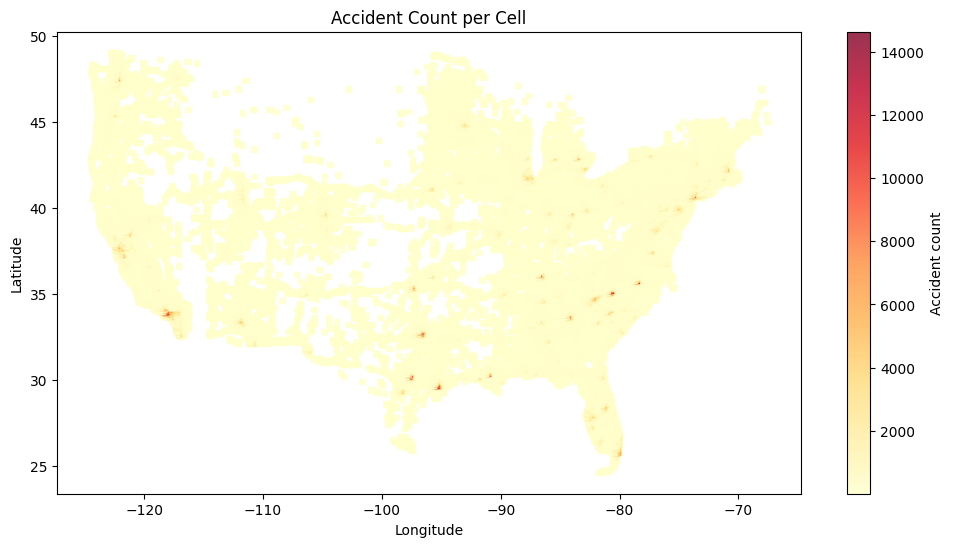

In [ ]:
## Where accidents happen, by grid cell
# Split "24.555_-81.78" into latitude and longitude numbers
table[['lat', 'lng']] = table['cell'].str.split('_', expand=True).astype(float)

# Each square is one cell, coloured by how many accidents it had
plt.figure(figsize=(12, 6))
points = plt.scatter(table['lng'], table['lat'],
                     c=table['accident_count'], cmap='YlOrRd',
                     s=15, marker='s', alpha=0.8)
plt.colorbar(points, label='Accident count')
plt.title('Accident Count per Cell')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

### 4.6 Prepare features and split
Only features the app can actually get: **time** (phone clock) and **road features** (map data such as OpenStreetMap).

In [ ]:
from sklearn.model_selection import train_test_split

"""
  Create the train and test split
"""
# print(table)
# model_df = pd.get_dummies(table, columns=['time_band'], dtype=int) #Binary Encoding
model_df = table
# print(model_df)
feature_cols = [c for c in model_df.columns if c.endswith('_share') or c.startswith('time_band_')]

X = model_df[feature_cols]
X = X.drop(columns="Visibility(mi)_share")
y = model_df['accident_count']
groups = model_df['cell']      # used later for the 'new area' check

"""
  Stratify to make data split sort of evenly between the train and test

"""
X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups, test_size=0.2, random_state=42)

print('Features:', feature_cols)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Features: ['Junction_share', 'Traffic_Signal_share', 'Crossing_share', 'Stop_share', 'Station_share', 'Amenity_share', 'Railway_share', 'Temperature(F)_share', 'Humidity(%)_share', 'Pressure(in)_share', 'Visibility(mi)_share']
Train: (17188, 10)  Test: (4297, 10)


### 4.7 Base model: Random Forest + stratified 5-fold cross-validation
**Stratified** = every fold keeps the same Low/Medium/High mix. We score with **macro F1** (treats all three classes equally) rather than accuracy, because the classes are not balanced.

In [ ]:
import numpy as np
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

# 1. Setup the Random Forest regressor with the specified parameters
rf_base = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_split=2,
    random_state=42,
)

# 2. Wrap it with log transformation for the target variable
wrapper_model = TransformedTargetRegressor(
    regressor=rf_base,
    func=np.log1p,
    inverse_func=np.expm1,
)

# 3. Fit the model directly on the training data
wrapper_model.fit(X_train, y_train)

# 4. Generate predictions on the test data
predictions = wrapper_model.predict(X_test)

# 5. Evaluate on the original scale
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mae = mean_absolute_error(y_test, predictions)
mape = mean_absolute_percentage_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

# 6. Print evaluation results
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape * 100:.2f}%")
print(f"R² Score: {r2:.4f}")

Root Mean Squared Error (RMSE): 329.3870
Mean Absolute Error (MAE): 61.1852
Mean Absolute Percentage Error (MAPE): 88.23%
R² Score: 0.5673


Number of feature names: 10
Number of importances: 10
--- Feature Importances ---
             Feature  Importance
      Junction_share    0.350597
Traffic_Signal_share    0.326131
      Crossing_share    0.094527
          Stop_share    0.084728
Temperature(F)_share    0.038213
   Humidity(%)_share    0.036479
       Amenity_share    0.021925
  Pressure(in)_share    0.020014
       Station_share    0.014572
       Railway_share    0.012814


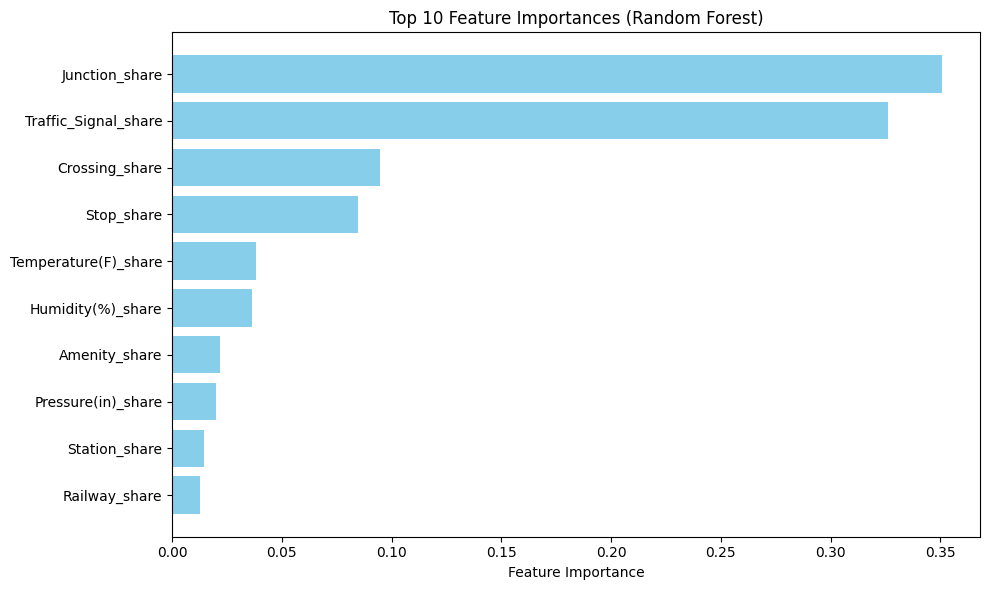

In [ ]:
# ==========================================
# 6. Extract and Display Feature Importances
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names directly from X_train columns
feature_names = X_train.columns

# Extract the trained RandomForestRegressor from wrapper_model
trained_rf = wrapper_model.regressor_
importances = trained_rf.feature_importances_

# Safety check: print lengths to verify they match
print(f"Number of feature names: {len(feature_names)}")
print(f"Number of importances: {len(importances)}")

# Create a DataFrame for clean sorting and viewing
feature_importance_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": importances}
).sort_values(by="Importance", ascending=False)

print("--- Feature Importances ---")
print(feature_importance_df.to_string(index=False))

# Optional: Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance_df["Feature"][:10][::-1],
    feature_importance_df["Importance"][:10][::-1],
    color="skyblue",
)
plt.xlabel("Feature Importance")
plt.title("Top 10 Feature Importances (Random Forest)")
plt.tight_layout()
plt.show()

### 4.8 Compare models (same data, same folds, same metric)

                   Mean R2    Std
Model                            
Ridge Regression    -0.603  1.075
Baseline (mean)     -0.036  0.004
KNN                  0.229  0.018
Decision Tree        0.447  0.022
Gradient Boosting    0.559  0.033
Random Forest        0.602  0.030


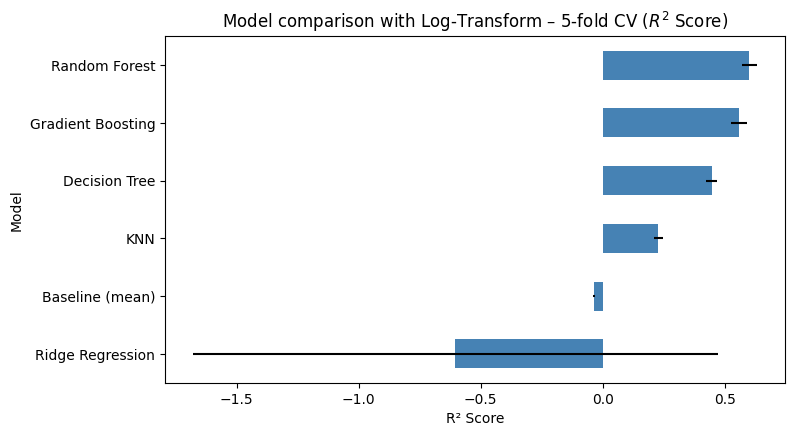

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

# Helper function to easily wrap any model with a log1p target transformation
def wrap_with_log(model):
    return TransformedTargetRegressor(
        regressor=model,
        func=np.log1p,
        inverse_func=np.expm1,
    )

# 1. Define the regression models dictionary, wrapping each with the log-transformer
models = {
    'Baseline (mean)': wrap_with_log(DummyRegressor(strategy='mean')),
    'Ridge Regression': wrap_with_log(make_pipeline(StandardScaler(), Ridge(random_state=42))),
    'KNN': wrap_with_log(make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15))),
    'Decision Tree': wrap_with_log(DecisionTreeRegressor(max_depth=6, random_state=42)),
    'Random Forest': wrap_with_log(RandomForestRegressor(random_state=42)),
    'Gradient Boosting': wrap_with_log(HistGradientBoostingRegressor(random_state=42)),
}

# 2. Setup standard KFold cross-validation for regression
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Evaluate models using cross-validation (evaluates on original scale automatically)
results = []
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='r2')
    results.append({'Model': name, 'Mean R2': s.mean(), 'Std': s.std()})

# 4. Format results into a DataFrame and sort
results = pd.DataFrame(results).set_index('Model').sort_values('Mean R2')
print(results.round(3))

# 5. Plot the comparison
results['Mean R2'].plot(
    kind='barh',
    xerr=results['Std'],
    figsize=(8, 4.5),
    color='steelblue',
)
plt.title('Model comparison with Log-Transform – 5-fold CV ($R^2$ Score)')
plt.xlabel('R² Score')
plt.show()